# Task 2 — Dự báo 5 giờ bằng Encoder–Decoder

Dùng 48 giờ ETTh1 với target OT, dự đoán **t+1 đến t+5** bằng Encoder–Decoder LSTM có attention và residual.

Đã có test độc lập cho cấu hình cuối với **3 seed: 42, 123, 2026**.

Notebook trình bày dữ liệu, kiến trúc và kết quả đã đo. `TRAIN=False` xem lại kết quả, không tự huấn luyện lại.

## Chuẩn bị

Dùng PyTorch cho model; pandas và matplotlib để xem dữ liệu. Các hàm đọc kết quả và vận hành được để trong helper như notebook M1.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd()/"src/utils.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT/"src"))
from notebook_support import (
    load_run, setup_plots, layer_shapes, load_weights, training_settings,
    validation_comparison, prepare_training, train_presented_model
)

setup_plots()
torch.set_num_threads(2)
TRAIN = False
TASK = "task2"
run = load_run(TASK, architecture="legacy")
settings = run["config"]
torch.manual_seed(settings["seed"])

## 1. Đọc và kiểm tra dữ liệu

**ETTh1:** 17.420 quan sát theo giờ, 7 biến số. `OT` là biến cần dự đoán; sáu biến còn lại là các phép đo tải điện. Dữ liệu được giữ đúng thứ tự thời gian.

In [2]:
data = pd.read_csv(ROOT/"data/raw/etth1/ETTh1.csv", parse_dates=["date"])
display(data.head())
print("Số quan sát:", len(data))
print("Khoảng thời gian:", data.date.min(), "→", data.date.max())
print("Giá trị thiếu:", data.isna().sum().sum())
print("Timestamp trùng:", data.date.duplicated().sum())
print("Khoảng cách thời gian:", data.date.diff().dropna().unique())

,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001
2,2016-07-01 02:00:00,5.157,1.741,1.279,0.355,3.777,1.218,27.787001
3,2016-07-01 03:00:00,5.090,1.942,1.279,0.391,3.807,1.279,25.044001
4,2016-07-01 04:00:00,5.358,1.942,1.492,0.462,3.868,1.279,21.948000


Số quan sát: 17420
Khoảng thời gian: 2016-07-01 00:00:00 → 2018-06-26 19:00:00
Giá trị thiếu: 0
Timestamp trùng: 0
Khoảng cách thời gian: <TimedeltaArray>
['0 days 01:00:00']
Length: 1, dtype: timedelta64[us]


## 2. EDA trên tập train

Chỉ dùng 70% đầu để tìm hiểu phân bố, tương quan và độ trễ. Các nhận xét này tạo giả thuyết; quyết định giữ cải tiến phải dựa trên validation.

,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
count,12194.00,12194.00,12194.00,12194.00,12194.00,12194.00,12194.00
mean,7.44,1.96,4.55,0.69,2.92,0.78,16.29
std,6.35,2.11,6.16,1.93,1.19,0.66,8.35
min,-19.62,-4.76,-21.96,-5.93,-1.19,-1.37,-4.08
25%,5.96,0.34,3.59,-0.71,2.16,0.64,10.06
50%,8.44,1.81,5.83,0.71,2.68,0.94,15.12
75%,11.12,3.42,8.24,2.17,3.35,1.19,20.68
max,23.64,10.11,17.34,7.57,8.50,3.05,46.01


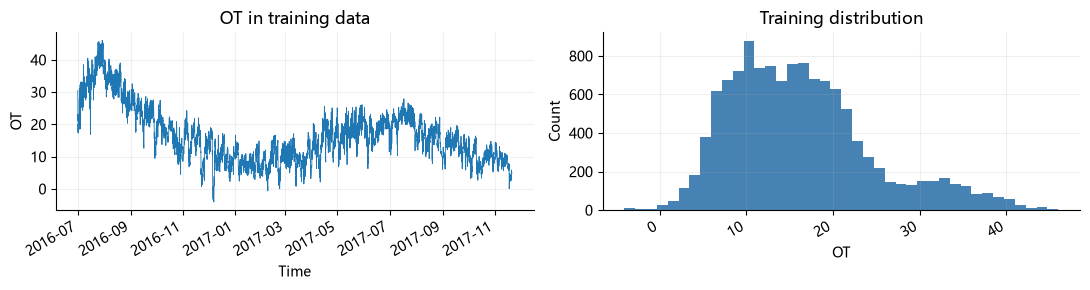

In [3]:
train_end = int(len(data) * 0.70)
validation_end = int(len(data) * 0.85)
train_data = data.iloc[:train_end]
display(train_data.drop(columns="date").describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].plot(train_data.date, train_data.OT, linewidth=0.6)
axes[0].set(title="OT in training data", xlabel="Time", ylabel="OT")
axes[1].hist(train_data.OT, bins=40, color="steelblue")
axes[1].set(title="Training distribution", xlabel="OT", ylabel="Count")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**Read the two plots above:** the left line follows training OT through calendar time; the right histogram counts hourly readings in each OT interval. The changing level and spread explain why a forecast needs recent history. A histogram describes values, not forecast accuracy.

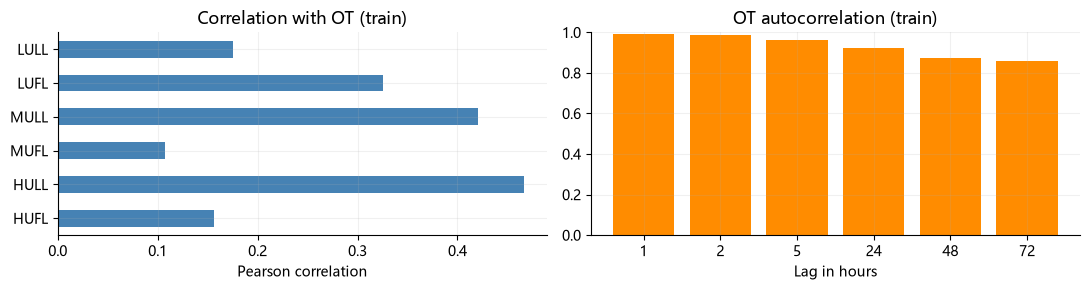

,Lag (giờ),Autocorrelation
0,1,0.993
1,2,0.985
2,5,0.963
3,24,0.925
4,48,0.876
5,72,0.857


In [4]:
correlations = train_data.drop(columns="date").corr()["OT"].drop("OT")
lags = [1, 2, 5, 24, 48, 72]
autocorrelation = [train_data.OT.autocorr(lag) for lag in lags]

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
correlations.plot.barh(ax=axes[0], color="steelblue")
axes[0].set(title="Correlation with OT (train)", xlabel="Pearson correlation")
axes[1].bar([str(lag) for lag in lags], autocorrelation, color="darkorange")
axes[1].set(title="OT autocorrelation (train)", xlabel="Lag in hours", ylim=(0, 1))
plt.tight_layout()
plt.show()
display(pd.DataFrame({"Lag (giờ)": lags, "Autocorrelation": autocorrelation}).round(3))

**Read the plots above:** the left bars are same-hour Pearson correlations between each load variable and OT; longer bars indicate stronger linear association, not causation. The right bars compare OT with its own earlier values. High lag-1 autocorrelation explains why persistence is a strong baseline; lag-24 correlation alone does not prove daily seasonality.

### A concrete five-hour forecast

The last observed hour is t. All five targets occur after t. This example uses only training data; the model will learn to predict the orange points from the blue history.

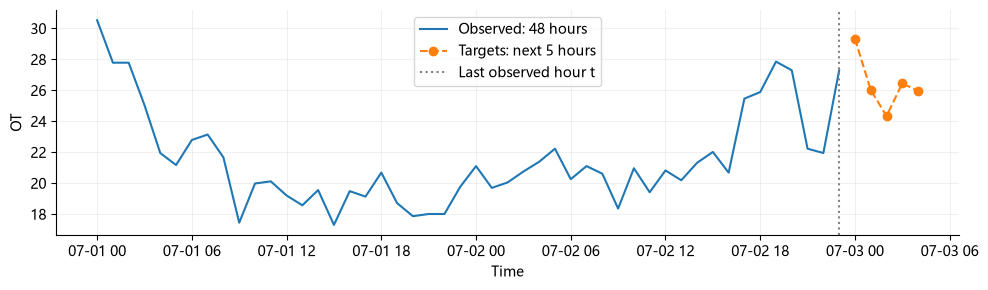

In [5]:
example = train_data.iloc[:53]
plt.figure(figsize=(10, 3))
plt.plot(example.date.iloc[:48], example.OT.iloc[:48], label="Observed: 48 hours")
plt.plot(example.date.iloc[48:], example.OT.iloc[48:], "o--", label="Targets: next 5 hours")
plt.axvline(example.date.iloc[47], color="grey", linestyle=":", label="Last observed hour t")
plt.xlabel("Time")
plt.ylabel("OT")
plt.legend()
plt.tight_layout()
plt.show()

The blue line contains the 48 observed values available to the model. The dotted line marks the last observed hour t. The five orange markers are the true values at t+1 to t+5; they are targets for learning, not predictions produced by this illustration.

### Why compare with persistence and learn a correction?

For each horizon, calculate future OT minus the last observed OT on training data. Larger corrections make a constant forecast harder. This motivates a residual hypothesis; validation measurements decide whether to retain it.

,MAE,RMSE
t+1,0.6920,1.0182
t+2,1.0186,1.4321
t+3,1.2832,1.7545
t+4,1.5194,2.0337
t+5,1.7198,2.2608


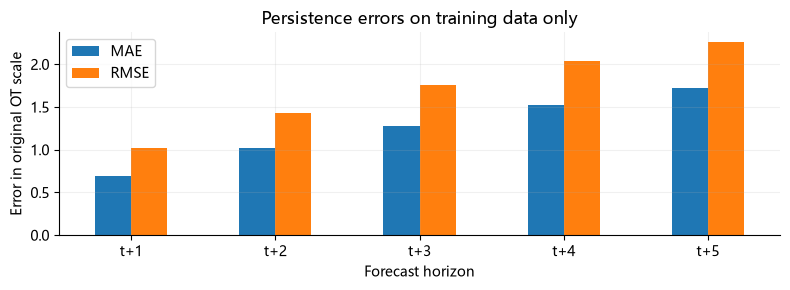

In [6]:
changes = pd.DataFrame({f"t+{h}": train_data.OT.shift(-h) - train_data.OT
                        for h in range(1, 6)}).dropna()
training_baseline = pd.DataFrame({"MAE": changes.abs().mean(),
                                   "RMSE": np.sqrt(changes.pow(2).mean())})
display(training_baseline.round(4))
training_baseline.plot.bar(figsize=(8, 3), rot=0)
plt.title("Persistence errors on training data only")
plt.xlabel("Forecast horizon")
plt.ylabel("Error in original OT scale")
plt.tight_layout()
plt.show()

Blue bars show persistence MAE; orange bars show RMSE, which gives more weight to large mistakes. Errors are in the original OT scale. The increase across horizons shows that repeating the last value becomes less accurate further ahead. These are training-only baseline errors; the model’s held-out test results appear later.

**Ý nghĩa cho mô hình:** OT gần đây là baseline mạnh, vì vậy cần so với persistence. Tự tương quan ở độ trễ dài có thể do cả xu hướng chậm; chưa đủ để kết luận có chu kỳ 24 giờ. Các hướng kiểm tra là input 24/48/72 giờ, OT đơn lẻ so với nhiều biến, và dự báo phần thay đổi (residual). Không coi các hướng chưa chạy là đã cải thiện điểm.

## 3. Chia dữ liệu và tạo cửa sổ

Chia 70% / 15% / 15% theo thời gian. Scaler chỉ fit train; mỗi cửa sổ nằm trọn trong một tập. Input có 48 giờ × 7 biến. `t` là timestamp cuối đã quan sát.

In [7]:
from utils import prepare_forecast
parts, scalers, horizons, identity = prepare_forecast(TASK, settings)
partitions = [data.iloc[:train_end], data.iloc[train_end:validation_end],
              data.iloc[validation_end:]]
split_table = []
for split, frame in zip(["train", "validation", "test"], partitions):
    split_table.append({"Tập": split, "Dòng gốc": len(frame),
                        "Từ": frame.date.iloc[0], "Đến": frame.date.iloc[-1],
                        "X shape": str(parts[split]["X"].shape),
                        "y shape": str(parts[split]["y"].shape)})
display(pd.DataFrame(split_table))
origin = pd.Timestamp(parts["train"]["origins"][0])
display(pd.DataFrame({"Horizon": horizons,
                      "Quan sát cuối t": origin,
                      "Target timestamp": parts["train"]["targets"][0]}))

,Tập,Dòng gốc,Từ,Đến,X shape,y shape
0,train,12194,2016-07-01 00:00:00,2017-11-21 01:00:00,"(12142, 48, 7)","(12142, 5)"
1,validation,2613,2017-11-21 02:00:00,2018-03-09 22:00:00,"(2561, 48, 7)","(2561, 5)"
2,test,2613,2018-03-09 23:00:00,2018-06-26 19:00:00,"(2561, 48, 7)","(2561, 5)"


,Horizon,Quan sát cuối t,Target timestamp
0,1,2016-07-02 23:00:00,2016-07-03 00:00:00
1,2,2016-07-02 23:00:00,2016-07-03 01:00:00
2,3,2016-07-02 23:00:00,2016-07-03 02:00:00
3,4,2016-07-02 23:00:00,2016-07-03 03:00:00
4,5,2016-07-02 23:00:00,2016-07-03 04:00:00


Ví dụ: input kết thúc tại 23:00 thì năm target là 00:00–04:00 ngày tiếp theo. Nhãn dự báo không xuất hiện trong input. StandardScaler chỉ fit train; metric cuối được đưa về thang OT gốc.

## 4. Xây dựng mô hình

`B` là batch size, `H` là hidden size. Dùng cùng dot-product attention: query so với các trạng thái đầu vào, softmax tạo trọng số, rồi lấy tổng có trọng số. Đây là một attention head, không phải MultiHeadAttention.

In [8]:
def dot_attention(query, memory):
    # query [B, outputs, H]; memory [B, input_positions, H].
    scores = torch.bmm(query, memory.transpose(1, 2)) / np.sqrt(memory.shape[-1])
    weights = scores.softmax(dim=-1)
    return torch.bmm(weights, memory), weights

**Luồng:** encoder LSTM nhận `[B,48,7]` → memory và hidden/cell → lặp context 5 lần → decoder LSTM `[B,5,128]` → cross-attention → Linear dùng chung → cộng OT cuối → `[B,5]`. Decoder nhận context và state của encoder, không nhận nhãn tương lai.

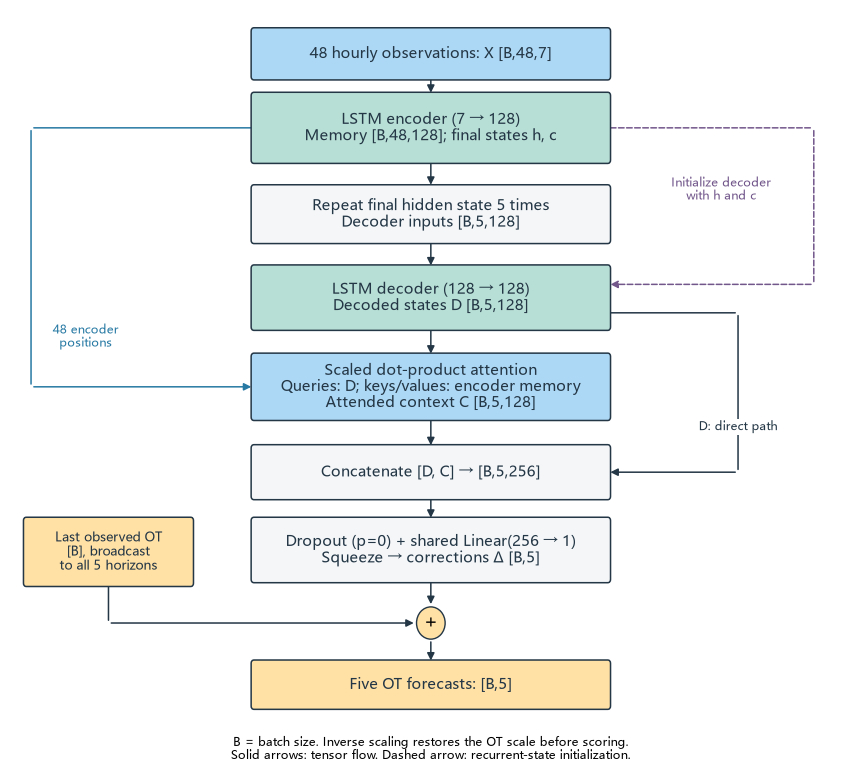

In [9]:
from model_diagrams import draw_task2_architecture
draw_task2_architecture()
plt.show()

**Read the architecture diagram:** the encoder sends its final hidden/cell states to initialize the decoder (dashed path), and its 48-step memory to attention (long side path). Five decoder states are concatenated with five attention contexts. The shared Linear layer predicts corrections; the separate last-OT input is added to every correction. Values inside the model are standardized; evaluation later restores the original OT scale.

In [10]:
class ForecastSeq2Seq(nn.Module):
    def __init__(self, features, config):
        super().__init__()
        h = config["hidden_size"]
        self.attention = config["attention"]
        self.residual = config["residual"]
        self.encoder = nn.LSTM(features, h, batch_first=True)
        self.decoder = nn.LSTM(h, h, batch_first=True)
        self.dropout = nn.Dropout(config["dropout"])
        self.output = nn.Linear(2*h if self.attention else h, 1)
        if self.residual:
            nn.init.zeros_(self.output.weight)
            nn.init.zeros_(self.output.bias)

    def forward(self, X, last):
        memory, (hidden, cell) = self.encoder(X)
        repeated_context = hidden[-1][:, None].repeat(1, 5, 1)
        decoded, _ = self.decoder(repeated_context, (hidden, cell))
        if self.attention:
            context, _ = dot_attention(decoded, memory)
            decoded = torch.cat([decoded, context], dim=-1)
        prediction = self.output(self.dropout(decoded)).squeeze(-1)  # [batch, 5]
        if self.residual:
            prediction = prediction + last[:, None]
        return prediction

In [11]:
model = ForecastSeq2Seq(len(scalers["features"]), settings)
if not TRAIN:
    load_weights(model, run)
X_example = torch.from_numpy(parts["validation"]["X"][:2])
last_example = torch.from_numpy(parts["validation"]["last"][:2])
layers, prediction = layer_shapes(model, X_example, last_example)
print(model)
display(layers)
print("Output:", tuple(prediction.shape))
print("Số tham số:", sum(p.numel() for p in model.parameters()))

ForecastSeq2Seq(
  (encoder): LSTM(7, 128, batch_first=True)
  (decoder): LSTM(128, 128, batch_first=True)
  (dropout): Dropout(p=0.0, inplace=False)
  (output): Linear(in_features=256, out_features=1, bias=True)
)


,Layer,Input,Output,Parameters
0,encoder (LSTM),"(2, 48, 7)","(2, 48, 128)",70144
1,decoder (LSTM),"(2, 5, 128)","(2, 5, 128)",132096
2,dropout (Dropout),"(2, 5, 256)","(2, 5, 256)",0
3,output (Linear),"(2, 5, 256)","(2, 5, 1)",257


Output: (2, 5)
Số tham số: 202497


Bảng trên là shape đi qua **layer thật** trên hai mẫu, không phải bảng shape viết tay. Attention, phép lấy trung bình và cộng residual là phép toán trong `forward`, nên cần đọc cùng sơ đồ và code phía trên.

## 5. Loss và huấn luyện

Thông số bên dưới thuộc run đã đo, không phải cấu hình recovery mới. Checkpoint được chọn bằng validation, không lấy epoch cuối một cách mặc định.

In [12]:
display(training_settings(run))

,Thông số,Giá trị
0,Seed,42.000
1,Hidden size,128.000
2,Batch run này,64.000
3,Learning rate ban đầu,0.001
4,Epoch tối đa,60.000
5,Early-stopping patience,8.000
6,Epoch đã chạy,13.000
7,Epoch checkpoint tốt nhất,5.000
8,Thời gian train (giây),17.300
9,Số tham số,202497.000


MSE trên OT đã chuẩn hóa. Khi đánh giá, inverse scale để tính sai số ở đơn vị gốc.

Hàm dưới đây là một bước cập nhật **được dùng trong vòng lặp train thật** của project. Ô này chỉ định nghĩa hàm, không tự train.

In [13]:
def forecast_train_step(model, optimizer, X, y, last):
    optimizer.zero_grad(set_to_none=True)
    prediction = model(X, last)
    loss = nn.functional.mse_loss(prediction, y)
    if not torch.isfinite(loss):
        raise RuntimeError("Non-finite forecasting training loss")
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.)
    optimizer.step()
    return loss.item()

In [14]:
if TRAIN:
    model = prepare_training(model, settings["seed"])
optimizer = torch.optim.Adam(model.parameters(), lr=settings["learning_rate"])
print("Adam — learning rate ban đầu:", settings["learning_rate"])

Adam — learning rate ban đầu: 0.001


In [15]:
if TRAIN:
    run = train_presented_model(TASK, model, optimizer, settings, parts=parts, scalers=scalers)
    display(training_settings(run))
history = run["history"]

history_columns = ['epoch', 'train_loss', 'val_RMSE', 'lr']
display(history[history_columns].tail(5).round(4))

,epoch,train_loss,val_RMSE,lr
8,9,0.0287,1.1127,0.0010
9,10,0.0272,1.1024,0.0005
10,11,0.0265,1.1914,0.0005
11,12,0.0261,1.3232,0.0005
12,13,0.0254,1.3951,0.0005


## 6. Validation và lựa chọn cấu hình

So sánh ở seed 42 trước, chọn bằng validation. Chỉ cấu hình cuối mới được lặp thêm seed; không chọn seed theo điểm test. Learning curve dưới đây là run được phân tích ở trên.

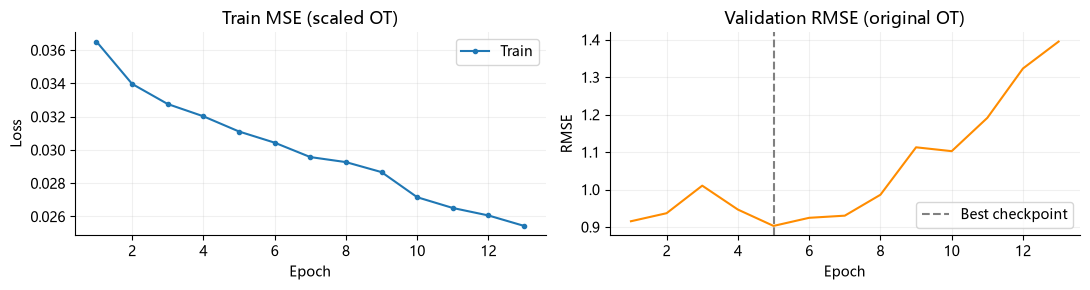

,Cấu hình,Validation RMSE,Được chọn
7,seq64,1.0094,False
8,seq64_attention,0.9880,False
9,seq64_residual,0.9403,False
10,seq64_attention_residual,0.9451,False
11,seq128_attention_residual,0.9029,True
12,seq64_attention_residual_lr3e4,0.9317,False
13,seq64_attention_residual_OT,0.9184,False


In [16]:
best_epoch = run["metadata"]["best_epoch"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].plot(history.epoch, history.train_loss, marker="o", markersize=3, label="Train")
axes[0].set(xlabel="Epoch", ylabel="Loss")

axes[0].set_title("Train MSE (scaled OT)")
axes[1].plot(history.epoch, history.val_RMSE, color="darkorange")
axes[1].set(title="Validation RMSE (original OT)", xlabel="Epoch", ylabel="RMSE")

axes[0].legend()
axes[1].axvline(best_epoch, linestyle="--", color="grey", label="Best checkpoint")
axes[1].legend()
plt.tight_layout()
plt.show()
display(validation_comparison(TASK))

### How the evidence leads to the final model

| Evidence | Decision |
| --- | --- |
| Ordered hourly observations and short-term continuity | Use an LSTM and retain persistence as a strong baseline. |
| Five future values are required | Use a real five-step recurrent decoder. |
| Training changes motivate corrections | Test residual forecasting; retain it based on validation. |
| Attention helps some configurations but not all | Compare measured validation RMSE, rather than assume a benefit. |
| seq128_attention_residual has the lowest measured validation RMSE | Freeze that configuration, then report three seeds on test. |

The 48-hour input is a design choice. Lookbacks 24/72 were not fully benchmarked, so EDA does not establish that 48 is optimal. New training-only EDA explains the saved experiment; it is not a new model-selection experiment.

MSE train và RMSE validation có thang đo khác nhau nên vẽ hai trục riêng. Bảng so sánh cho thấy attention không luôn giúp: ở Task 2, `seq64_attention_residual` kém `seq64_residual`; cấu hình H=128 mới cho validation tốt nhất. Vì vậy không quy mọi cải thiện cho attention.

## 7. Benchmark test cuối

**R²/NSE càng cao càng tốt; MAE/RMSE càng thấp càng tốt.** R² là hệ số xác định, không phải phần trăm accuracy. R² và NSE dùng cùng công thức residual nên bằng nhau. Bảng chính dùng mean ± sample std của đúng ba seed; baseline là công thức xác định, không phải ba model đã train.

**Macro:** tính metric riêng cho từng horizon rồi trung bình đều. **Pooled:** gộp mọi dự đoán rồi tính một lần. RMSE macro và pooled khác nhau; benchmark chính dùng macro. Mỗi horizon có 2.561 cặp test.

In [17]:
from notebook_support import forecast_benchmark, benchmark_tables
benchmark = forecast_benchmark(TASK)
final_table, seed_table, improvement = benchmark_tables(benchmark)
display(final_table)
display(seed_table)
print(f"Giảm RMSE so với persistence: {improvement:.2f}%")
print("Mục tiêu trong plan: giảm ít nhất 5% —", "ĐẠT" if improvement >= 5 else "CHƯA ĐẠT")

,Mô hình,R2,NSE,MAE,RMSE
0,Persistence,0.8287,0.8287,0.8063,1.1363
1,Daily seasonal,0.3574,0.3574,1.7067,2.2802
2,Model — mean ± std (3 seed),0.8749 ± 0.0038,0.8749 ± 0.0038,0.6869 ± 0.0230,0.9823 ± 0.0171


,R2,NSE,MAE,RMSE
seed,,,,
42,0.8789,0.8789,0.6642,0.9649
123,0.8743,0.8743,0.6864,0.9830
2026,0.8715,0.8715,0.7102,0.9991


Giảm RMSE so với persistence: 13.55%
Mục tiêu trong plan: giảm ít nhất 5% — ĐẠT


In [18]:
per_horizon = benchmark[benchmark.horizon.str.startswith("t+")]
network = per_horizon[per_horizon.model.eq("model")]
means = network.groupby("horizon")[["R2", "NSE", "MAE", "RMSE"]].mean()
means["RMSE std"] = network.groupby("horizon").RMSE.std()
persistence = per_horizon[per_horizon.model.eq("persistence")].groupby("horizon").RMSE.first()
means["Persistence RMSE"] = persistence
means["Giảm RMSE (%)"] = 100 * (1-means.RMSE/persistence)
display(means.round(4))
pooled = benchmark[benchmark.model.eq("model") & benchmark.horizon.eq("pooled")]
print(f"Pooled RMSE, 3 seed: {pooled.RMSE.mean():.4f} ± {pooled.RMSE.std():.4f}")

,R2,NSE,MAE,RMSE,RMSE std,Persistence RMSE,Giảm RMSE (%)
horizon,,,,,,,
t+1,0.9481,0.9481,0.4515,0.6472,0.0319,0.6586,1.7353
t+2,0.9110,0.9110,0.5776,0.8483,0.0235,0.9449,10.2175
t+3,0.8734,0.8734,0.6979,1.0120,0.0182,1.1789,14.1568
t+4,0.8377,0.8377,0.8079,1.1460,0.0121,1.3713,16.4312
t+5,0.8043,0.8043,0.8998,1.2581,0.0117,1.5277,17.6504


Pooled RMSE, 3 seed: 1.0059 ± 0.0151


## 8. Xem dự đoán và sai số

Hình dùng 240 dự đoán test đầu tiên theo thời gian của seed 42, không chọn các đoạn đẹp. Bảng nhỏ hiển thị target timestamp và sai số thực tế.

,target_time,horizon,actual,predicted,absolute_error
0,2018-03-11 23:00:00,1,7.668,7.3261,0.3419
1,2018-03-12 00:00:00,2,8.020,7.2808,0.7392
2,2018-03-12 01:00:00,3,7.949,7.1675,0.7815
3,2018-03-12 02:00:00,4,7.597,7.0562,0.5408
4,2018-03-12 03:00:00,5,7.668,6.9719,0.6961


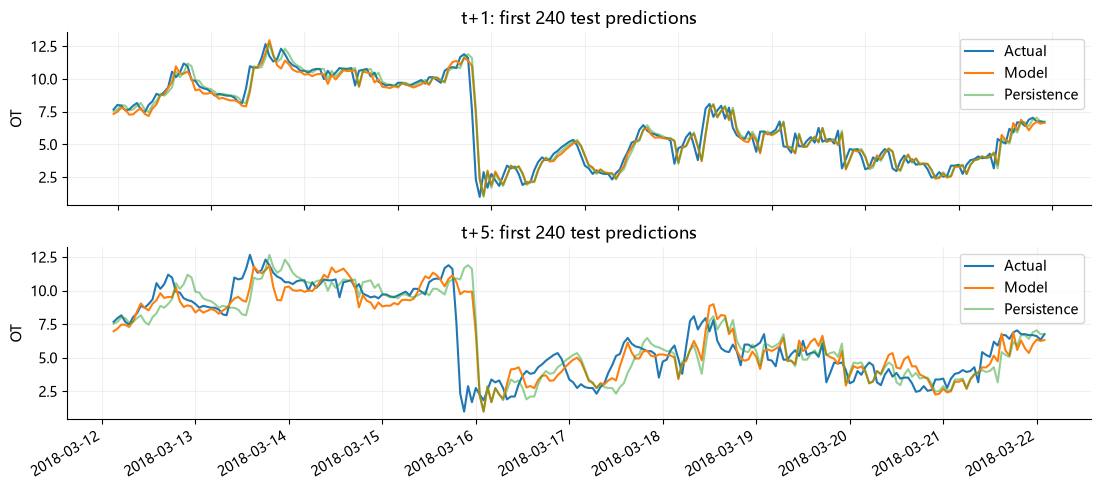

In [19]:
predictions = run["predictions"].copy()
predictions["target_time"] = pd.to_datetime(predictions.target_time)
predictions["absolute_error"] = abs(predictions.actual-predictions.predicted)
columns = ["target_time", "horizon", "actual", "predicted", "absolute_error"]
display(predictions[columns].head().round({"actual": 4, "predicted": 4, "absolute_error": 4}))

fig, axes = plt.subplots(2, 1, figsize=(11, 5))
for ax, horizon in zip(axes, [1, 5]):
    values = predictions[predictions.horizon.eq(horizon)].head(240)
    ax.plot(values.target_time, values.actual, label="Actual")
    ax.plot(values.target_time, values.predicted, label="Model")
    ax.plot(values.target_time, values.persistence, label="Persistence", alpha=.5)
    ax.set(title=f"t+{horizon}: first 240 test predictions", ylabel="OT")
    ax.legend()
fig.autofmt_xdate()

plt.tight_layout()
plt.show()

## 9. Đánh giá kết quả

Test macro **R²=0,8749**, **RMSE=0,9823 ± 0,0171**; giảm RMSE **13,55%** so với persistence, đạt mục tiêu 5% của plan. t+5 khó hơn: RMSE trung bình **1,2581**, R² **0,8043**. Đây là hạn chế thực tế cần trình bày, không giấu trong một số trung bình.

Các hướng chưa chạy như lookback 24/72 giờ vẫn là đề xuất. Những thay đổi tiếp theo phải chọn bằng validation mới; không tinh chỉnh theo test đã xem.

### Nguồn

[ETDataset — tác giả công bố ETTh1](https://github.com/zhouhaoyi/ETDataset). Notebook dùng cách chia 70/15/15 đã ghi trong plan; đây là benchmark nội bộ của project, không tự nhận là cùng giao thức của mọi bài báo. Chi tiết dữ liệu: [data/raw/README.md](../data/raw/README.md).